# LeafVision crop baseline

This notebook runs the saved MobileNetV2 classifier on the original test split and on the subset filtered by exact image content. It also shows the training and validation losses recorded by the original notebook.

Use Python 3.12 with the project requirements and an IPython kernel. Place the checkpoint, original archives, and portable splits in the locations documented in the project README. A full run reads both archives and batches all 4,179 original test images on CPU. [Project setup](../README.md) · [Original training notebook, sections 10–11](ml_summative_notebook.ipynb)

In [1]:
import csv
import io
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import Markdown, display
from PIL import Image

root = next((path for path in (Path.cwd(), Path.cwd().parent)
             if (path / "scripts/evaluate_crop.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Start the kernel from the repository root or notebook directory")
sys.path.insert(0, str(root))

from scripts.audit_image_hashes import ARCHIVES
from scripts.evaluate_crop import evaluate
from src import CROP_CLASSES
from src.preprocessing import preprocess_jpeg

artifacts = root / "artifacts"
checkpoint = artifacts / "best_crop_mobilenetv2.keras"
archives = artifacts / "archives"
splits = artifacts / "splits"
required = [checkpoint, *(archives / name for name in ARCHIVES.values()),
            *(splits / f"{split}.csv" for split in ("train", "val", "test"))]
missing = [str(path.relative_to(root)) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Prepare the inputs from the README first: " + ", ".join(missing))

print(f"TensorFlow {tf.__version__} | Keras {tf.keras.__version__}")
print("Output classes:", ", ".join(CROP_CLASSES))

TensorFlow 2.21.0 | Keras 3.15.1
Output classes: cashew, cassava, maize, rice, tomato


## Original training and optimization

The original crop model starts from ImageNet-pretrained MobileNetV2 and fine-tunes its last 30 backbone layers. Its head uses global average pooling, 30% dropout, and a five-class softmax. Training used Adam with a learning rate of 0.0001 and sparse categorical cross-entropy. Early stopping monitored validation loss with patience 3 and restored the best weights. The original notebook logs a minimum validation loss at epoch 7. The cell below plots the historical logged values. [Original training notebook, sections 10.6 and 11.1](ml_summative_notebook.ipynb)

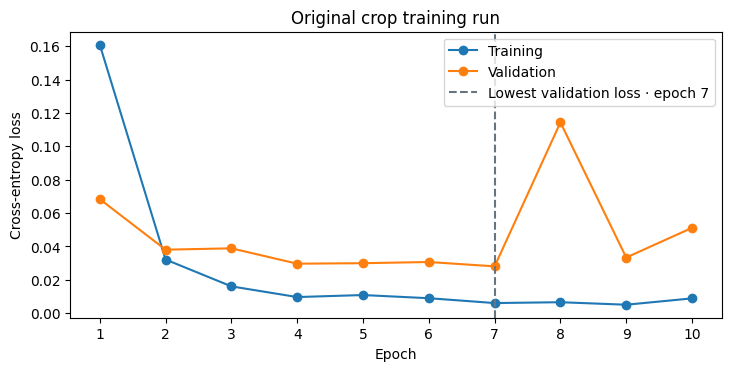

In [2]:
epochs = range(1, 11)
train_loss = [0.1609, 0.0321, 0.0160, 0.0096, 0.0108, 0.0089, 0.0060, 0.0065, 0.0050, 0.0088]
validation_loss = [0.0683, 0.0380, 0.0388, 0.0296, 0.0299, 0.0306, 0.0280, 0.1143, 0.0333, 0.0511]

fig, ax = plt.subplots(figsize=(7.2, 3.6), layout="constrained")
ax.plot(epochs, train_loss, "o-", label="Training")
ax.plot(epochs, validation_loss, "o-", label="Validation")
best = int(np.argmin(validation_loss)) + 1
ax.axvline(best, color="#667580", linestyle="--", label=f"Lowest validation loss · epoch {best}")
ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Original crop training run", xticks=list(epochs))
ax.legend()
plt.show()

## Run a labeled prediction

The shared preprocessor decodes JPEGs as RGB and resizes them to 128 × 128. The checkpoint rescales the 0–255 pixel values internally. The example comes directly from the original rice archive, and its expected label comes from the test manifest.

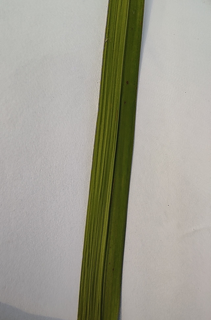

Expected: rice | Predicted: rice | Score: 1.000000


In [3]:
sample_path = "rice/Rice Dataset/Original Dataset/Healthy/HL_423.jpg"
with (splits / "test.csv").open(newline="", encoding="utf-8") as stream:
    sample = next(row for row in csv.DictReader(stream) if row["path"] == sample_path)
source, member = sample["path"].split("/", 1)
with zipfile.ZipFile(archives / ARCHIVES[source]) as archive:
    data = archive.read(member)

model = tf.keras.models.load_model(checkpoint, compile=False, safe_mode=True)
image = preprocess_jpeg(data)
scores = model(image[tf.newaxis, ...], training=False).numpy()[0]
prediction = CROP_CLASSES[int(scores.argmax())]
preview = Image.open(io.BytesIO(data))
preview.thumbnail((320, 320))
display(preview)
print(f"Expected: {sample['crop']} | Predicted: {prediction} | Score: {scores.max():.6f}")
assert prediction == sample["crop"]

## Evaluate both test subsets

The evaluator recomputes SHA-256 groups from the images, excludes test hashes shared with training or validation, and keeps the first manifest row per remaining hash. It predicts once per image on the original test split and scores the retained predictions again. Macro precision, recall, and F1 weight all five crops equally.

In [4]:
report = evaluate(checkpoint, splits, archives)
print("Checkpoint SHA-256:", report["checkpoint_sha256"])

lines = [
    "| Test set | Correct / total | Accuracy | Macro precision | Macro recall | Macro F1 | Mean loss |",
    "| --- | ---: | ---: | ---: | ---: | ---: | ---: |",
]
for label, key in (("Original", "original"), ("SHA-256 filtered", "hash_filtered")):
    row = report[key]
    lines.append(
        f"| {label} | {row['correct']:,} / {row['images']:,} | {row['accuracy']:.3%} "
        f"| {row['macro_precision']:.5f} | {row['macro_recall']:.5f} "
        f"| {row['macro_f1']:.5f} | {row['mean_cross_entropy']:.5f} |"
    )
display(Markdown("\n".join(lines)))

assert (report["original"]["correct"], report["original"]["images"]) == (4135, 4179)
assert (report["hash_filtered"]["correct"], report["hash_filtered"]["images"]) == (3883, 3926)

Checkpoint SHA-256: 9bb1658122b2383ddb111dc35cfdb6b713e92954776ee5e67d0bff899f4b9d21


| Test set | Correct / total | Accuracy | Macro precision | Macro recall | Macro F1 | Mean loss |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Original | 4,135 / 4,179 | 98.947% | 0.98987 | 0.99158 | 0.99067 | 0.04236 |
| SHA-256 filtered | 3,883 / 3,926 | 98.905% | 0.98942 | 0.99125 | 0.99028 | 0.04485 |

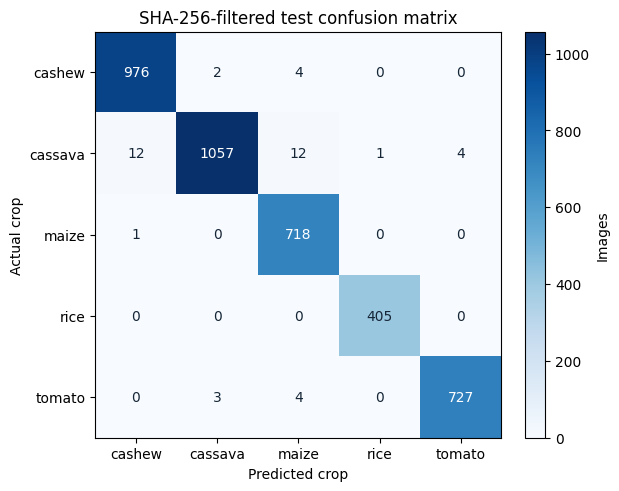

In [5]:
matrix = np.array(report["hash_filtered"]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6.2, 4.8), layout="constrained")
plot = ax.imshow(matrix, cmap="Blues")
ticks = np.arange(len(CROP_CLASSES))
ax.set(xticks=ticks, yticks=ticks, xticklabels=CROP_CLASSES, yticklabels=CROP_CLASSES,
       xlabel="Predicted crop", ylabel="Actual crop", title="SHA-256-filtered test confusion matrix")
for i, j in np.ndindex(matrix.shape):
    color = "white" if matrix[i, j] > matrix.max() / 2 else "#162637"
    ax.text(j, i, str(matrix[i, j]), ha="center", va="center", color=color)
fig.colorbar(plot, ax=ax, label="Images")
plt.show()

## Interpret the baseline

Cassava accounts for 29 of the 43 errors in the SHA-256-filtered test subset. The targeted visual review also found 13 retained test images that likely repeat training photographs with different file bytes. Excluding those reviewed images gives 98.901% on 3,913 images. That sensitivity check covers the reviewed pairs.

Rice came from a different dataset. Its training photos had a median of 82.7% near-white pixels, and their framing and resolution differed from the other crops. These conditions could help the model distinguish rice on this benchmark. Performance on field photos from new sources remains an open question. [Dataset analysis and review methods](../README.md)